**Тема «Предсказание предпочтений человека между ответами LLM»**

*Цель*: понять, почему человек выбирает один ответ модели, а не другой. Действительно ли дело в содержании, или на выбор сильно влияет то, как ответ выглядит: длина, списки, заголовки, форматирование.

Задача: по двум ответам разных моделей на один и тот же вопрос предсказать, какой из них человек посчитает лучше. Модель смотрит только на внешние признаки текста, которые я считаю обычным pandas, смысл ответов она не понимает.

Планируемый результат: модель, которая угадывает выбор человека с точностью выше случайного угадывания (50%). Станет видно, что сильнее влияет на выбор - длина ответа, списки или что-то еще. Сравнение трех моделей: логистическая регрессия, дерево решений, случайный лес по метрикам на трех выборках.

Инструменты: Python, pandas и NumPy для работы с данными, matplotlib и seaborn для графиков, scikit-learn для моделей и метрик. Работаю в Google Colab.

В качестве данных использую Chatbot Arena Human Preference (LMArena), https://huggingface.co/datasets/lmarena-ai/arena-human-preference-55k

Тему выбрал потому, что работаю AI-тренером и по работе ранжирую ответы моделей. Хочу проверить, насколько оценка человека на самом
деле зависит от формы ответа, а не от смысла.

In [1]:
!pip install -q datasets

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

In [3]:
ds = load_dataset("lmarena-ai/arena-human-preference-55k")
df = ds["train"].to_pandas()
df.shape

(57477, 9)

In [4]:
df.columns

Index(['id', 'model_a', 'model_b', 'prompt', 'response_a', 'response_b',
       'winner_model_a', 'winner_model_b', 'winner_tie'],
      dtype='object')

In [5]:
df[["winner_model_a", "winner_model_b", "winner_tie"]].sum()

,0
winner_model_a,20064
winner_model_b,19652
winner_tie,17761


In [6]:
print(df["response_a"][0])

["The question of whether it is morally right to aim for a certain percentage of females in managerial positions is a complex ethical issue that involves considerations of fairness, equality, diversity, and discrimination.\n\nHere are some arguments in favor of and against such policies:\n\n**Arguments in favor:**\n\n1. **Correcting Historical Inequities:** Women have historically been underrepresented in leadership roles due to various cultural, institutional, and social barriers. Aiming for a specific percentage can be seen as a corrective measure to address past and ongoing discrimination.\n\n2. **Promoting Diversity:** Diverse leadership teams can enhance decision-making and represent a broader range of perspectives. This can lead to better outcomes for organizations and society as a whole.\n\n3. **Equality of Opportunity:** Setting targets for female representation in management can help ensure that women have equal opportunities to advance in their careers.\n\n4. **Role Modeling:

In [7]:
df = df[df["winner_tie"] == 0].copy()
df["target"] = df["winner_model_a"]
df.shape

(39716, 10)

In [8]:
print(df["response_a"].iloc[0])

["The question of whether it is morally right to aim for a certain percentage of females in managerial positions is a complex ethical issue that involves considerations of fairness, equality, diversity, and discrimination.\n\nHere are some arguments in favor of and against such policies:\n\n**Arguments in favor:**\n\n1. **Correcting Historical Inequities:** Women have historically been underrepresented in leadership roles due to various cultural, institutional, and social barriers. Aiming for a specific percentage can be seen as a corrective measure to address past and ongoing discrimination.\n\n2. **Promoting Diversity:** Diverse leadership teams can enhance decision-making and represent a broader range of perspectives. This can lead to better outcomes for organizations and society as a whole.\n\n3. **Equality of Opportunity:** Setting targets for female representation in management can help ensure that women have equal opportunities to advance in their careers.\n\n4. **Role Modeling:

In [9]:
import json

def extract_text(raw):
    parts = json.loads(raw)
    parts = [p for p in parts if isinstance(p, str)]
    return " ".join(parts)

df["text_a"] = df["response_a"].apply(extract_text)
df["text_b"] = df["response_b"].apply(extract_text)

df[["text_a", "text_b"]].head()

,text_a,text_b
0,The question of whether it is morally right to...,"As an AI, I don't have personal beliefs or opi..."
1,A marriage license is a legal document that al...,A marriage license and a marriage certificate ...
3,Creating a test set for a very rare category c...,When building a classifier for a very rare cat...
4,The best way to travel from Tel Aviv to Jerusa...,The best way to travel from Tel-Aviv to Jerusa...
5,"[Zeus]\nYo, it's the king of the gods on the m...","(Verse 1 - Zeus)\n\nI'm the king of the gods, ..."


In [10]:
(df["text_a"].str.strip() == "").sum()

np.int64(18)

In [11]:
(df["text_b"].str.strip() == "").sum()

np.int64(18)

In [12]:
df = df[(df["text_a"].str.strip() != "") & (df["text_b"].str.strip() != "")].copy()
df.shape

(39687, 12)

57477 → убрали ничьи → 39716 → убрали пустые ответы → 39687

In [13]:
df["len_a"] = df["text_a"].str.len()
df["len_b"] = df["text_b"].str.len()
df["len_diff"] = df["len_a"] - df["len_b"]

df[["len_a", "len_b", "len_diff", "target"]].head()

,len_a,len_b,len_diff,target
0,4459,1200,3259,1
1,3096,3592,-496,0
3,3165,1550,1615,1
4,1290,760,530,0
5,916,1932,-1016,0


In [14]:
df.groupby("target")["len_diff"].mean()

,len_diff
target,
0,-269.167380
1,248.698888


In [15]:
df.groupby("target")["len_diff"].median()

,len_diff
target,
0,-155.0
1,150.0


In [16]:
df[["len_diff", "target"]].corr()

,len_diff,target
len_diff,1.000000,0.231931
target,0.231931,1.000000


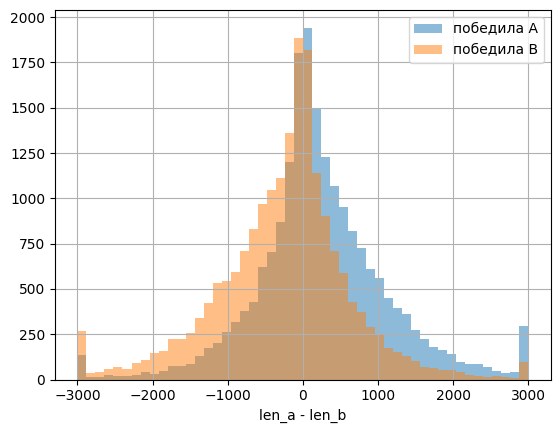

In [17]:
import matplotlib.pyplot as plt

df[df["target"] == 1]["len_diff"].clip(-3000, 3000).hist(bins=50, alpha=0.5, label="победила A")
df[df["target"] == 0]["len_diff"].clip(-3000, 3000).hist(bins=50, alpha=0.5, label="победила B")
plt.legend()
plt.xlabel("len_a - len_b")
plt.show()

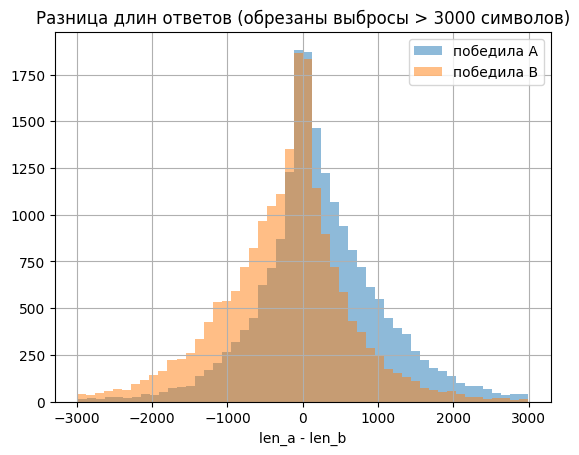

In [18]:
subset = df[df["len_diff"].abs() < 3000]

subset[subset["target"] == 1]["len_diff"].hist(bins=50, alpha=0.5, label="победила A")
subset[subset["target"] == 0]["len_diff"].hist(bins=50, alpha=0.5, label="победила B")
plt.legend()
plt.xlabel("len_a - len_b")
plt.title("Разница длин ответов (обрезаны выбросы > 3000 символов)")
plt.show()

In [19]:
(df["len_diff"].abs() >= 3000).sum()

np.int64(700)

In [20]:
def count_features(text):
    return pd.Series({
        "len": len(text),
        "words": len(text.split()),
        "lines": text.count("\n"),
        "bullets": text.count("\n-") + text.count("\n*") + text.count("\n•"),
        "numbered": text.count("\n1.") + text.count("\n2.") + text.count("\n3."),
        "headers": text.count("#"),
        "code": text.count("```"),
        "bold": text.count("**"),
    })

In [21]:
feat_a = df["text_a"].apply(count_features)
feat_b = df["text_b"].apply(count_features)

diff = feat_a - feat_b
diff.columns = [c + "_diff" for c in diff.columns]

data = pd.concat([diff, df["target"]], axis=1)
data.head()

,len_diff,words_diff,lines_diff,bullets_diff,numbered_diff,headers_diff,code_diff,bold_diff,target
0,3259,469,34,4,6,0,0,24,1
1,-496,-40,-19,0,-2,0,0,0,0
3,1615,276,5,0,0,0,0,0,1
4,530,110,-2,3,0,0,0,0,0
5,-1016,-171,-26,0,0,0,0,0,0


In [22]:
data.corr()["target"].sort_values()

,target
headers_diff,0.016344
code_diff,0.021400
bullets_diff,0.058162
bold_diff,0.080744
numbered_diff,0.099518
lines_diff,0.189991
words_diff,0.229092
len_diff,0.231931
target,1.000000


In [23]:
data.corr()

,len_diff,words_diff,lines_diff,bullets_diff,numbered_diff,headers_diff,code_diff,bold_diff,target
len_diff,1.000000,0.976664,0.648817,0.168886,0.366830,0.082581,0.063239,0.341102,0.231931
words_diff,0.976664,1.000000,0.618345,0.181114,0.365168,0.084350,0.050596,0.293761,0.229092
lines_diff,0.648817,0.618345,1.000000,0.345670,0.251267,0.100626,0.163909,0.252700,0.189991
bullets_diff,0.168886,0.181114,0.345670,1.000000,-0.173071,0.049158,0.002463,0.162542,0.058162
numbered_diff,0.366830,0.365168,0.251267,-0.173071,1.000000,-0.003388,0.036950,0.153849,0.099518
headers_diff,0.082581,0.084350,0.100626,0.049158,-0.003388,1.000000,0.014466,0.067780,0.016344
code_diff,0.063239,0.050596,0.163909,0.002463,0.036950,0.014466,1.000000,0.019736,0.021400
bold_diff,0.341102,0.293761,0.252700,0.162542,0.153849,0.067780,0.019736,1.000000,0.080744
target,0.231931,0.229092,0.189991,0.058162,0.099518,0.016344,0.021400,0.080744,1.000000


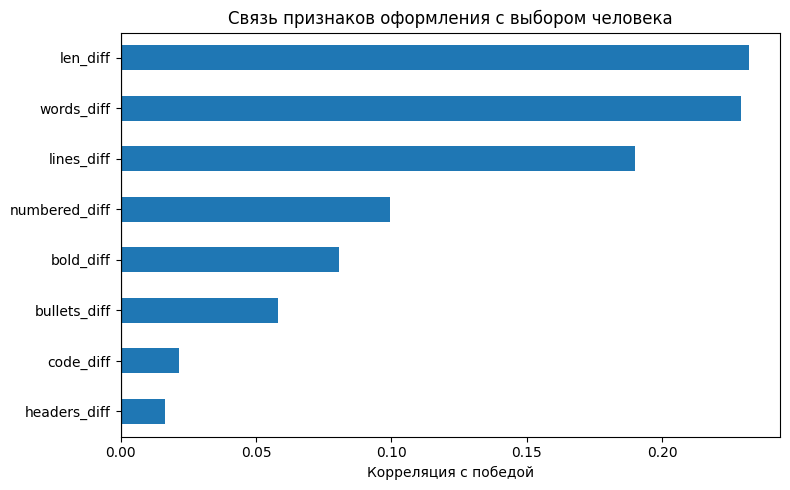

In [24]:
corr_target = data.corr()["target"].drop("target").sort_values()

plt.figure(figsize=(8, 5))
corr_target.plot(kind="barh")
plt.xlabel("Корреляция с победой")
plt.title("Связь признаков оформления с выбором человека")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.model_selection import train_test_split

features = ["len_diff", "lines_diff", "bullets_diff",
            "numbered_diff", "headers_diff", "code_diff", "bold_diff"]

X = data[features]
y = data["target"]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp)

print(X_train.shape, X_val.shape, X_test.shape)

(27795, 7) (5938, 7) (5954, 7)


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_sc, y_train)

print("train accuracy:", accuracy_score(y_train, logreg.predict(X_train_sc)))
print("val accuracy:  ", accuracy_score(y_val, logreg.predict(X_val_sc)))
print("val ROC-AUC:   ", roc_auc_score(y_val, logreg.predict_proba(X_val_sc)[:, 1]))

train accuracy: 0.6205792408706602
val accuracy:   0.6131694173122263
val ROC-AUC:    0.6567176650782846


Около 61% человеческих предпочтений воспроизводится моделью, которая вообще не читает ответы, а смотрит только на их длину и оформление.

In [27]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print("train:  ", accuracy_score(y_train, rf.predict(X_train)))
print("val:    ", accuracy_score(y_val, rf.predict(X_val)))
print("ROC-AUC:", roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1]))

train:   0.6603705702464472
val:     0.613001010441226
ROC-AUC: 0.6640644996596325


In [28]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
print(imp)

headers_diff     0.038374
code_diff        0.044713
bold_diff        0.058714
numbered_diff    0.064422
bullets_diff     0.070544
lines_diff       0.275678
len_diff         0.447555
dtype: float64


In [29]:
from sklearn.tree import DecisionTreeClassifier

tree_deep = DecisionTreeClassifier(random_state=42)
tree_deep.fit(X_train, y_train)
print("Без ограничений — train:", accuracy_score(y_train, tree_deep.predict(X_train)))
print("Без ограничений — val:  ", accuracy_score(y_val, tree_deep.predict(X_val)))

tree_lim = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_lim.fit(X_train, y_train)
print("max_depth=5 — train:", accuracy_score(y_train, tree_lim.predict(X_train)))
print("max_depth=5 — val:  ", accuracy_score(y_val, tree_lim.predict(X_val)))

Без ограничений — train: 0.9242309767943875
Без ограничений — val:   0.5394072078140788
max_depth=5 — train: 0.6272351142291779
max_depth=5 — val:   0.615527113506231


In [30]:
for d in [4, 6, 8, 10, 12]:
    rf = RandomForestClassifier(n_estimators=200, max_depth=d, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    tr = accuracy_score(y_train, rf.predict(X_train))
    vl = accuracy_score(y_val, rf.predict(X_val))
    auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
    print(f"depth={d:2d}  train={tr:.3f}  val={vl:.3f}  auc={auc:.3f}")

depth= 4  train=0.626  val=0.616  auc=0.667
depth= 6  train=0.633  val=0.618  auc=0.667
depth= 8  train=0.645  val=0.616  auc=0.666
depth=10  train=0.660  val=0.613  auc=0.664
depth=12  train=0.678  val=0.614  auc=0.663


In [31]:
results = pd.DataFrame({
    "модель": ["Логистическая регрессия", "Дерево (без ограничений)",
               "Дерево (max_depth=5)", "Случайный лес"],
    "train": [0.621, 0.924, 0.627, 0.660],
    "val":   [0.613, 0.539, 0.616, 0.613],
})
results

,модель,train,val
0,Логистическая регрессия,0.621,0.613
1,Дерево (без ограничений),0.924,0.539
2,Дерево (max_depth=5),0.627,0.616
3,Случайный лес,0.660,0.613


In [32]:
best = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)
best.fit(X_train, y_train)

print("train:", accuracy_score(y_train, best.predict(X_train)))
print("val:  ", accuracy_score(y_val, best.predict(X_val)))
print("test: ", accuracy_score(y_test, best.predict(X_test)))
print("test ROC-AUC:", roc_auc_score(y_test, best.predict_proba(X_test)[:, 1]))

train: 0.633387299874078
val:   0.6180532165712361
test:  0.626301645952301
test ROC-AUC: 0.6773973861059353


Модель, не имеющая доступа к содержанию ответов и оперирующая только их длиной и оформлением, предсказывает выбор человека с точностью 62,6% и ROC-AUC 0.677 на отложенной тестовой выборке из 5954 пар. При этом 72% объясняющей силы приходится на объём ответа, и лишь 28% — на все элементы форматирования вместе взятые.